In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
from shapely.geometry import Point 
from matplotlib import pyplot as plt

# Spatial Aggregation

In [2]:
# load Naturraeume Brandenburg
NATRAUM = gpd.read_file("../data/brandenburg_shape/naturraum_scholz_ohne_Berlin.gpkg", layer="naturraum_scholz_ohne_berlin")

In [3]:
print(NATRAUM.crs)
print(NATRAUM.geom_type.value_counts().to_dict())
print(len(NATRAUM))
print(NATRAUM.total_bounds)
print(NATRAUM.columns)

EPSG:4326
{'MultiPolygon': 79}
79
[11.26601236 51.35826207 14.76432439 53.55806679]
Index(['AREA', 'PERIMETER', 'NR_HAUPT', 'NAME_HAUPT', 'NR_UNTER', 'NAME_UNTER',
       'FLäCHE', 'geometry'],
      dtype='str')


In [4]:
NATRAUM["NR_UNTER"].nunique()

75

In [5]:
natraum_3035 = NATRAUM.to_crs("EPSG:3035")

In [6]:
# load pr as example
pr = xr.open_dataset(Path("../data/imported")/"hyras_pr_v6-1_2001_2025.nc")
pr_da = pr["pr"]

In [7]:
# make a grid cell centre look up table 
x, y = np.meshgrid(pr_da.x.values, pr_da.y.values)

grid_points = gpd.GeoDataFrame(
    {
        "x": x.ravel(),
        "y": y.ravel()
    },
    geometry=[
        Point(xi, yi)
        for xi, yi in zip(x.ravel(), y.ravel())
    ],
    crs="EPSG:3035",
)

In [8]:
grid_natraum = gpd.sjoin(
    grid_points,
    natraum_3035[
        [
            "NR_HAUPT",
            "NAME_HAUPT",
            "NR_UNTER",
            "NAME_UNTER",
            "AREA",
            "geometry",
        ]
    ],
    how="left",
    predicate="within",
)

In [9]:
print(grid_natraum["NR_UNTER"].isna().sum())
print(grid_natraum["NR_UNTER"].sum())

40565
23885628.0


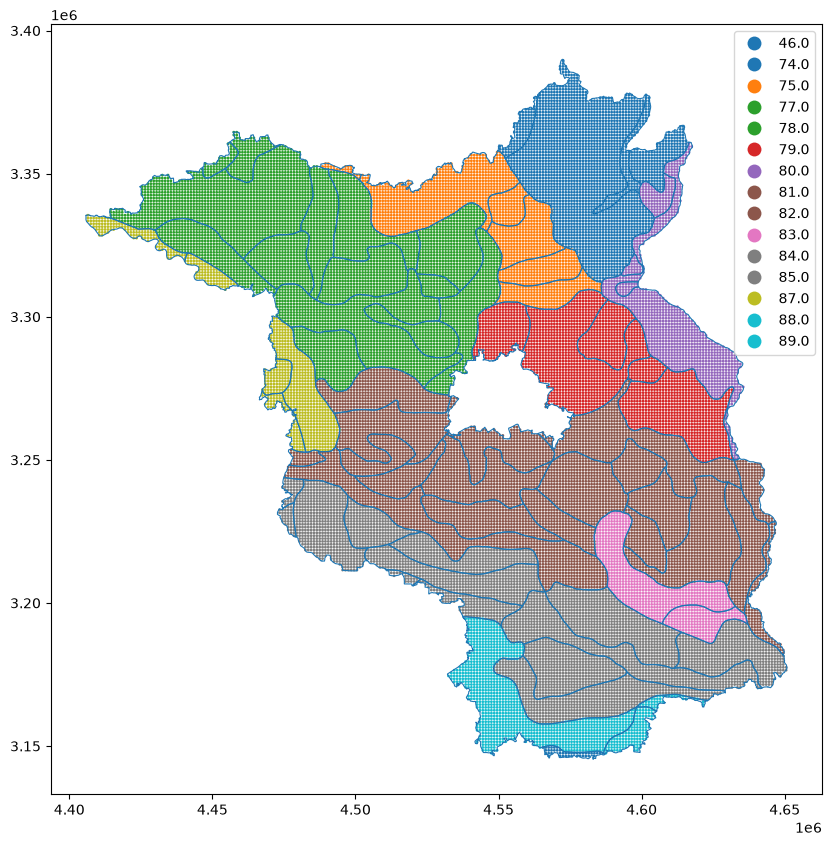

In [10]:
fig, ax = plt.subplots(figsize=(10, 10))

natraum_3035.boundary.plot(
    ax=ax,
    linewidth=0.8
)

grid_natraum.plot(
    ax=ax,
    column="NR_HAUPT",
    categorical=True,
    legend=True,
    markersize=1
)

plt.show()

In [11]:
# add unique identifier
natraum_3035["region_id"] = range(len(natraum_3035))
grid_natraum = gpd.sjoin(
    grid_points,
    natraum_3035[
        [
            "region_id",
            "NR_HAUPT",
            "NAME_HAUPT",
            "NR_UNTER",
            "NAME_UNTER",
            "AREA",
            "geometry",
        ]
    ],
    how="left",
    predicate="within",
)

In [12]:
grid_natraum[grid_natraum["region_id"].notnull()].head(3)
print(grid_natraum["region_id"].nunique())

79


In [13]:
# reshape to 2D array
region_ids = grid_natraum["region_id"].to_numpy().reshape(len(pr_da.y), len(pr_da.x))
region_ids

array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(265, 265))

In [14]:
pr_da.shape 

(9131, 265, 265)

In [15]:
region_id_da = xr.DataArray(region_ids, dims=("y", "x"), coords={"y": pr["y"], "x": pr["x"]}, name="region_id")
region_id_da 

<xarray.DataArray 'region_id' (y: 265, x: 265)> Size: 562kB
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(265, 265))
Coordinates:
  * y        (y) float64 2kB 3.136e+06 3.136e+06 3.138e+06 ... 3.398e+06 3.4e+06
  * x        (x) float64 2kB 4.396e+06 4.398e+06 4.398e+06 ... 4.66e+06 4.66e+06

In [16]:
# test pr aggregation by region_id
pr_region_daily = pr_da.groupby(region_id_da).mean(dim="stacked_y_x")
pr_region_daily

<xarray.DataArray 'pr' (time: 9131, region_id: 79)> Size: 3MB
array([[2.0617368e+00, 3.4216485e+00, 2.2074385e+00, ..., 1.6131580e+00,
        1.4466157e+00, 1.2441863e+00],
       [9.5276761e-01, 1.0123713e+00, 4.1157025e-01, ..., 2.1052634e-02,
        9.7744420e-02, 1.4418603e-01],
       [4.1020569e-01, 2.2371128e-01, 3.4297466e-01, ..., 9.0789473e-01,
        7.3383486e-01, 3.4883726e-02],
       ...,
       [3.0772558e-01, 5.0515439e-02, 4.3305787e-01, ..., 7.3421049e-01,
        1.7654136e+00, 2.2046521e+00],
       [2.2614419e-01, 5.5670083e-02, 2.5950420e-01, ..., 0.0000000e+00,
        0.0000000e+00, 4.6511628e-03],
       [1.8258061e+00, 1.9422685e+00, 1.7223141e+00, ..., 4.6105266e+00,
        5.6270666e+00, 4.3906980e+00]], shape=(9131, 79), dtype=float32)
Coordinates:
  * time       (time) datetime64[ns] 73kB 2001-01-01 2001-01-02 ... 2025-12-31
  * region_id  (region_id) float64 632B 0.0 1.0 2.0 3.0 ... 75.0 76.0 77.0 78.0
Attributes:
    standard_name:      thickness_of_rainfall_amount
    long_name:          Daily Precipitation Sum
    units:              mm
    CoordinateSystems:  LatLonCoordinateSystem ProjectionCoordinateSystem
    esri_pe_string:     PROJCS["ETRS_1989_LAEA",GEOGCS["GCS_ETRS_1989",DATUM[...
    grid_mapping:       crs
    cell_methods:       time: sum

In [17]:
pr_region_daily.region_id

<xarray.DataArray 'region_id' (region_id: 79)> Size: 632B
array([ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12., 13.,
       14., 15., 16., 17., 18., 19., 20., 21., 22., 23., 24., 25., 26., 27.,
       28., 29., 30., 31., 32., 33., 34., 35., 36., 37., 38., 39., 40., 41.,
       42., 43., 44., 45., 46., 47., 48., 49., 50., 51., 52., 53., 54., 55.,
       56., 57., 58., 59., 60., 61., 62., 63., 64., 65., 66., 67., 68., 69.,
       70., 71., 72., 73., 74., 75., 76., 77., 78.])
Coordinates:
  * region_id  (region_id) float64 632B 0.0 1.0 2.0 3.0 ... 75.0 76.0 77.0 78.0

In [20]:
pr_region_daily.shape

(9131, 79)

# Temporal Aggregation